# LiDAR Sensors and Point Clouds

**Module 01 · Perception Systems** · Notebook 3 of 8

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/01_Perception/03_lidar_point_clouds.ipynb)

| Level | Time | Prerequisites | Standards |
|---|---|---|---|
| Intermediate | ~75 min | [02 Sensor modalities](02_sensor_modalities.ipynb); basic linear algebra | IEC 60825-1:2014; ISO 8855:2011; ISO 21448:2022 |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

By the end of this notebook you will be able to:

1. Explain the physics of LiDAR ranging (pulsed time of flight, phase shift, FMCW) and the LiDAR range equation
2. Describe scanning mechanisms (spinning, mirror/prism scanning, MEMS, flash, OPA) and their trade-offs
3. Compute point density and the number of returns on an object as a function of distance
4. Transform points between sensor and vehicle frames and quantify the effect of extrinsic calibration error
5. Segment the ground and cluster obstacles in a point cloud
6. Identify LiDAR failure modes as SOTIF triggering conditions

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation
from IPython.display import display

rng = np.random.default_rng(42)
OKABE_ITO = ['#E69F00', '#56B4E9', '#009E73', '#F0E442', '#0072B2', '#D55E00', '#CC79A7', '#000000']
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.prop_cycle': plt.cycler(color=OKABE_ITO)})
C = 299_792_458.0   # speed of light [m/s]
print(f"NumPy {np.__version__}")

NumPy 2.5.4


## 1. Physical principles

LiDAR (Light Detection and Ranging) measures distance by emitting laser light and analysing the reflected signal: **emission → reflection → detection → range computation**.

### 1.1 Pulsed time of flight (ToF)

The range follows from the round-trip time $\Delta t$:

$$ d = \frac{c\,\Delta t}{2} $$

A target at 100 m returns after $\Delta t = 200\,\text{m} / c \approx 667$ ns. The range resolution is set by the timing resolution: $\Delta d = c\,\Delta t_{res}/2$, so 1 cm requires $\Delta t_{res} \approx 67$ ps.

**Properties**
- Long range (> 200 m for long-range units at high reflectivity) and cm-level accuracy.
- Range is measured directly; **velocity must be inferred from successive frames** (FMCW LiDAR measures per-point radial velocity via the Doppler effect).
- Challenges: picosecond timing electronics, ambient light (sunlight), multipath, interference from other LiDARs.

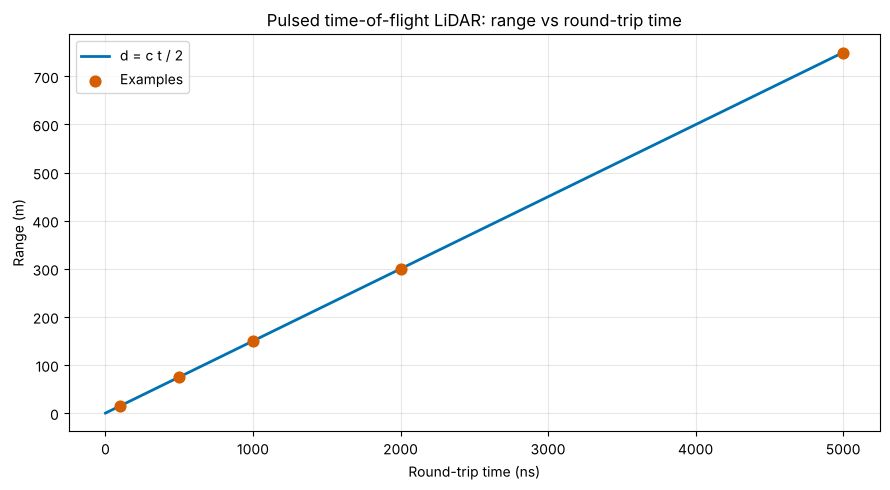

--- Time of flight (text summary) ---
    100 ns ->   14.99 m
    500 ns ->   74.95 m
   1000 ns ->  149.90 m
   2000 ns ->  299.79 m
   5000 ns ->  749.48 m
  Timing resolution for 1 cm range resolution: 67 ps


In [2]:
def tof_distance(travel_time_ns):
    """Range [m] from round-trip time [ns]."""
    return C * travel_time_ns * 1e-9 / 2

travel_times = np.array([100, 500, 1000, 2000, 5000])
distances = tof_distance(travel_times)
t = np.linspace(0, 5000, 200)

plt.figure(figsize=(9, 5))
plt.plot(t, tof_distance(t), color=OKABE_ITO[4], lw=2, label='d = c t / 2')
plt.scatter(travel_times, distances, color=OKABE_ITO[5], s=60, zorder=5, label='Examples')
plt.xlabel('Round-trip time (ns)'); plt.ylabel('Range (m)')
plt.title('Pulsed time-of-flight LiDAR: range vs round-trip time'); plt.legend()
plt.tight_layout(); plt.show()

print("--- Time of flight (text summary) ---")
for tt, dd in zip(travel_times, distances):
    print(f"  {tt:5.0f} ns -> {dd:7.2f} m")
print(f"  Timing resolution for 1 cm range resolution: {2*0.01/C*1e12:.0f} ps")

### 1.2 Phase shift (amplitude-modulated continuous wave)

For a sinusoidally modulated wave with modulation frequency $f$ and measured phase shift $\phi$:

$$ d = \frac{c\,\phi}{4\pi f}, \qquad d_{max} = \frac{c}{2f} $$

At $f = 10$ MHz the unambiguous range is 15 m. Several modulation frequencies are combined to resolve the ambiguity.

- **Pros:** high precision at short range (mm-level), lower peak power.
- **Cons:** limited unambiguous range (typically < 50 m without multi-frequency schemes); moving targets cause phase errors during the integration time.

### 1.3 FMCW (frequency-modulated continuous wave)

The laser frequency is swept (chirped); mixing the return with the outgoing light gives a beat frequency proportional to range, shifted by the Doppler frequency $2v_r/\lambda$. FMCW LiDAR therefore measures **range and radial velocity per point**, and is inherently resistant to interference from other sensors and sunlight. It typically uses 1550 nm lasers and coherent detection.

## 2. Scanning mechanisms

| Mechanism | How the beam is steered | Example products | Typical FOV (H) | Notes |
|---|---|---|---|---|
| **Spinning (rotating head)** | Whole laser/detector stack rotates | Velodyne HDL-64E (legacy), Ouster OS series, Hesai Pandar | 360° | Mature, surround view; moving parts |
| **Mirror / polygon scanning** | Rotating or oscillating mirrors | Luminar Iris; Hesai ATX | ~120° | Forward-facing, long range |
| **Risley prisms** | Two rotating wedge prisms | Livox | ~40–80° | Non-repetitive rosette pattern; coverage grows with integration time |
| **MEMS mirror** | Micro-mirror on a silicon chip | InnovizOne | ~100–120° | Few moving masses, compact |
| **Flash** | Whole scene illuminated at once; detector array | Short-range units | ~30–120° | No moving parts; short range (eye-safety power budget spread over FOV) |
| **Optical phased array (OPA)** | Phase-controlled emitter array | Mostly research / prototype stage | — | Fully solid-state |

Notes and corrections (as of October 2026):
- Velodyne merged with Ouster in February 2023 ([Ouster 10-K](https://www.sec.gov/Archives/edgar/data/1816581/000162828024013619/oust-20231231.htm)); Chinese suppliers such as Hesai and RoboSense now ship the largest volumes.
- Hesai's ATX (one-dimensional rotating mirror, ASIC-integrated lasers and detectors) is priced at about US\$200 in mass production since 2025 ([Reuters via LEDinside](https://www.ledinside.com/node/34820)). The cost trajectory is roughly ~US\$75k (HDL-64E, 2007) → ~US\$1k → ~US\$200.
- Luminar filed for Chapter 11 on 15 December 2025 after Volvo ended the EX90/ES90 supply agreement ([TechCrunch](https://techcrunch.com/2025/12/15/lidar-maker-luminar-files-for-bankruptcy)).
- Bosch ended its LiDAR development in 2023.
- Moving parts are a durability concern for automotive qualification; fewer or no moving parts generally improve robustness to vibration.

## 3. Specifications

### 3.1 Range and the LiDAR equation

Received power depends on transmit power $P_t$, target reflectivity $\rho$, atmospheric transmission $\tau$ (one way), receiver aperture area $A_r$, incidence angle $\alpha$ and distance $d$. For an **extended Lambertian target that fills the beam**, the beam divergence cancels:

$$ P_r = \frac{P_t\,\rho\,\tau^2\,A_r\cos\alpha}{\pi d^2} $$

For a **small target** (smaller than the beam footprint) the intercepted fraction itself falls with $d^2$, so $P_r \propto 1/d^4$. This is why datasheets quote range **at a stated reflectivity** (e.g. 10 %) — dark cars and dark clothing are the hard cases. Eye safety (IEC 60825-1, Class 1) caps $P_t$; 1550 nm lasers allow higher power than 905 nm but suffer stronger water absorption (rain, fog) and need costlier InGaAs detectors.

### 3.2 Accuracy, precision, resolution

- **Range accuracy** (systematic): typically ±2–5 cm; **precision** (random): ~1 cm at short range, degrading with distance and low reflectivity.
- **Angular resolution:** ~0.1–0.4° horizontal, ~0.1–2° vertical depending on the sensor.

### 3.3 Point density

For a spinning sensor with vertical FOV $\theta_v$ (radians), the scanned band at distance $d$ is a cylinder strip of area $(2\pi d)\cdot(d\,\theta_v)$. Points per revolution spread over this area:

$$ \rho_{points}(d) = \frac{N_{rev}}{2\pi d^2\,\theta_v} $$

**Worked example (HDL-64E class, 64 channels, 0.1° azimuth step at 10 Hz ≈ 2.3 M points/s):** $N_{rev} = 3600 \times 64 \approx 230{,}000$; $\theta_v = 26.9° = 0.4695$ rad; at 10 m the band area is $(2\pi \cdot 10) \cdot (10 \cdot 0.4695) \approx 295\ \text{m}^2$, so the density is $230{,}400 / 295 \approx 780$ points/m². (Using the fraction 26.9°/360° instead of radians would understate the area by a factor of 2π — a common mistake.)

Check of the worked example: 781 points/m^2 at 10 m


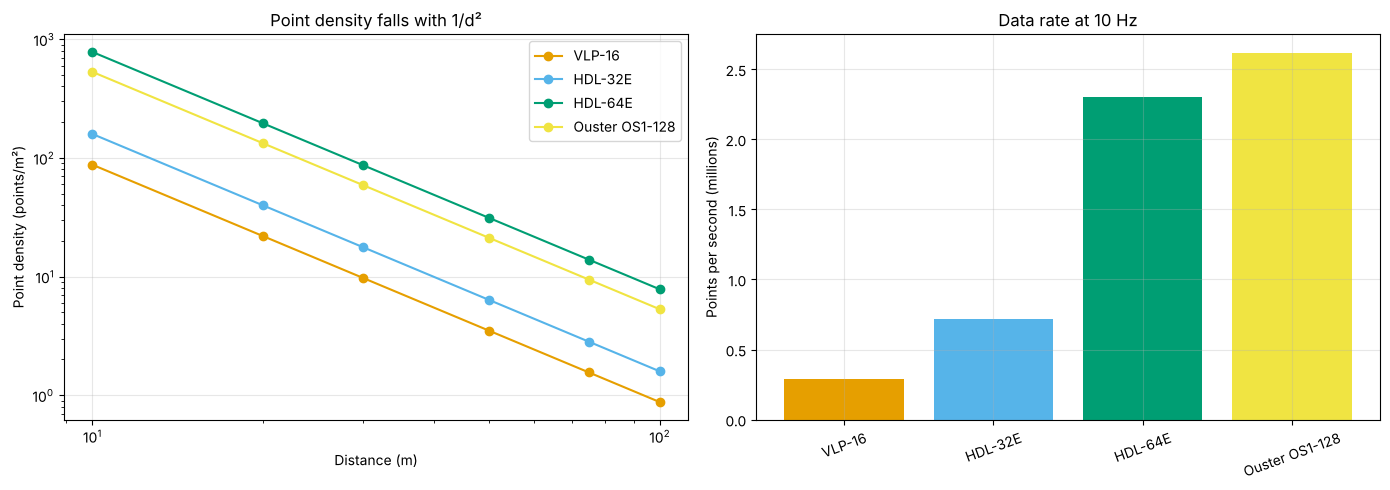

--- Point density (text summary) ---
  VLP-16          0.29 M pts/s | 10 m: 87.5, 20 m: 21.9, 30 m: 9.7, 50 m: 3.5, 75 m: 1.6, 100 m: 0.9 pts/m^2
  HDL-32E         0.72 M pts/s | 10 m: 159.0, 20 m: 39.7, 30 m: 17.7, 50 m: 6.4, 75 m: 2.8, 100 m: 1.6 pts/m^2
  HDL-64E         2.30 M pts/s | 10 m: 781.0, 20 m: 195.3, 30 m: 86.8, 50 m: 31.2, 75 m: 13.9, 100 m: 7.8 pts/m^2
  Ouster OS1-128  2.62 M pts/s | 10 m: 530.4, 20 m: 132.6, 30 m: 58.9, 50 m: 21.2, 75 m: 9.4, 100 m: 5.3 pts/m^2
  Going from 10 m to 100 m reduces density by a factor of 100 (= (100/10)^2).


In [3]:
def point_density(cfg, d):
    """Points per m^2 on a cylinder of radius d, and points per second."""
    pts_rev = int(round(360.0 / cfg['h_res_deg'])) * cfg['channels']
    pts_s = pts_rev * cfg['rotation_hz']
    area = (2 * np.pi * d) * (d * np.deg2rad(cfg['v_fov_deg']))
    return pts_rev / area, pts_s

# Approximate configurations at 10 Hz (azimuth step scales with spin rate; check the current datasheet)
sensors = {
    'VLP-16':         {'channels': 16,  'rotation_hz': 10, 'h_res_deg': 0.2,   'v_fov_deg': 30.0},
    'HDL-32E':        {'channels': 32,  'rotation_hz': 10, 'h_res_deg': 0.16,  'v_fov_deg': 41.3},
    'HDL-64E':        {'channels': 64,  'rotation_hz': 10, 'h_res_deg': 0.1,   'v_fov_deg': 26.9},
    'Ouster OS1-128': {'channels': 128, 'rotation_hz': 10, 'h_res_deg': 0.176, 'v_fov_deg': 45.0},
}
print(f"Check of the worked example: {point_density(sensors['HDL-64E'], 10)[0]:.0f} points/m^2 at 10 m")

dist = np.array([10, 20, 30, 50, 75, 100])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, cfg in sensors.items():
    axes[0].loglog(dist, [point_density(cfg, d)[0] for d in dist], 'o-', label=name)
axes[0].set_xlabel('Distance (m)'); axes[0].set_ylabel('Point density (points/m²)')
axes[0].set_title('Point density falls with 1/d²'); axes[0].legend()
pps = [point_density(c, 50)[1] for c in sensors.values()]
axes[1].bar(list(sensors), np.array(pps) / 1e6, color=OKABE_ITO[:4])
axes[1].set_ylabel('Points per second (millions)'); axes[1].set_title('Data rate at 10 Hz')
axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

print("--- Point density (text summary) ---")
for name, cfg in sensors.items():
    dens = [point_density(cfg, d)[0] for d in dist]
    print(f"  {name:15s} {point_density(cfg, 50)[1]/1e6:4.2f} M pts/s | " +
          ", ".join(f"{d} m: {v:.1f}" for d, v in zip(dist, dens)) + " pts/m^2")
ratio = point_density(sensors['HDL-64E'], 10)[0] / point_density(sensors['HDL-64E'], 100)[0]
print(f"  Going from 10 m to 100 m reduces density by a factor of {ratio:.0f} (= (100/10)^2).")

### 3.4 How many points land on a pedestrian?

Density matters because detectors need enough points to recognise an object. Below we ray-cast a 32-beam spinning sensor (0.2° azimuth step, vertical FOV −25° … +10°, mounted 1.8 m high) against a pedestrian-sized box (0.5 m × 0.5 m × 1.75 m) placed at increasing distances.

> **Illustrative data:** synthetic sensor and scene, chosen for teaching; not measurements.

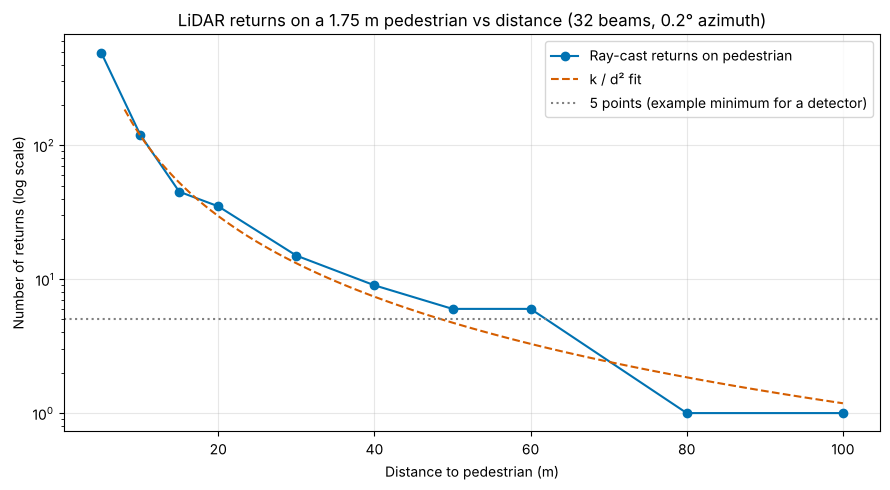

--- Returns on pedestrian (text summary) ---
     5 m:  493 returns
    10 m:  120 returns
    15 m:   45 returns
    20 m:   35 returns
    30 m:   15 returns
    40 m:    9 returns
    50 m:    6 returns
    60 m:    6 returns
    80 m:    1 returns
   100 m:    1 returns
  Farthest distance with at least 5 returns: 60 m
  The pedestrian's feet enter the lowest beam (-25 deg) only beyond 3.9 m: closer objects are partly in the near-field blind zone.


In [4]:
SENSOR_H = 1.8
G = -SENSOR_H

def ray_boxes(origin, dirs, boxes, ground_z=G, max_range=120.0):
    """First-hit distance and index of each ray against axis-aligned boxes and the ground.
    boxes: list of (xmin, xmax, ymin, ymax, zmin, zmax). Index -1 = ground, -2 = no hit."""
    n = len(dirs); t_best = np.full(n, np.inf); idx = np.full(n, -2)
    with np.errstate(divide='ignore', invalid='ignore'):
        inv = 1.0 / dirs
        for k, (x0, x1, y0, y1, z0, z1) in enumerate(boxes):
            t1 = (np.array([x0, y0, z0]) - origin) * inv; t2 = (np.array([x1, y1, z1]) - origin) * inv
            tmin = np.nanmax(np.minimum(t1, t2), axis=1); tmax = np.nanmin(np.maximum(t1, t2), axis=1)
            hit = (tmax >= np.maximum(tmin, 0)) & (tmin > 0) & (tmin < t_best)
            t_best[hit] = tmin[hit]; idx[hit] = k
        tg = (ground_z - origin[2]) / dirs[:, 2]
        hit = (dirs[:, 2] < 0) & (tg < t_best); t_best[hit] = tg[hit]; idx[hit] = -1
    far = t_best > max_range; t_best[far] = np.inf; idx[far] = -2
    return t_best, idx

def beam_dirs(n_beams=32, h_res_deg=0.2, v_fov=(-25.0, 10.0), az_window=None):
    az = np.arange(0, 360, h_res_deg)
    if az_window is not None:           # only simulate the azimuths that can hit the target (speed-up)
        az = az[(az >= az_window[0]) & (az <= az_window[1])]
    A, E = np.meshgrid(np.deg2rad(az), np.deg2rad(np.linspace(*v_fov, n_beams)))
    return np.stack([np.cos(E) * np.cos(A), np.cos(E) * np.sin(A), np.sin(E)], -1).reshape(-1, 3)

dists = np.array([5, 10, 15, 20, 30, 40, 50, 60, 80, 100])
hits = []
for d in dists:
    box = (d, d + 0.5, -0.25, 0.25, G, G + 1.75)
    half = np.rad2deg(np.arctan2(0.3, d)) + 0.5
    dirs = beam_dirs(az_window=(0, half))
    dirs = np.vstack([dirs, beam_dirs(az_window=(360 - half, 360))])
    tt, ii = ray_boxes(np.zeros(3), dirs, [box])
    hits.append(int((ii == 0).sum()))
hits = np.array(hits)

# Fit hits ~ k / d^2 on the distances where the whole pedestrian is inside the vertical FOV
full = dists >= 10
k = np.sum(hits[full] / dists[full]**2) / np.sum(1 / dists[full]**4)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(dists, hits, 'o-', color=OKABE_ITO[4], label='Ray-cast returns on pedestrian')
dd = np.linspace(8, 100, 100)
ax.plot(dd, k / dd**2, '--', color=OKABE_ITO[5], label='k / d² fit')
ax.axhline(5, color='grey', ls=':', label='5 points (example minimum for a detector)')
ax.set_yscale('log'); ax.set_xlabel('Distance to pedestrian (m)'); ax.set_ylabel('Number of returns (log scale)')
ax.set_title('LiDAR returns on a 1.75 m pedestrian vs distance (32 beams, 0.2° azimuth)'); ax.legend()
plt.tight_layout(); plt.show()

print("--- Returns on pedestrian (text summary) ---")
for d, h in zip(dists, hits):
    print(f"  {d:4d} m: {h:4d} returns")
last_ok = dists[hits >= 5].max() if (hits >= 5).any() else None
print(f"  Farthest distance with at least 5 returns: {last_ok} m")
d_min = SENSOR_H / np.tan(np.deg2rad(25.0))
print(f"  The pedestrian's feet enter the lowest beam (-25 deg) only beyond {d_min:.1f} m: closer objects are partly in the near-field blind zone.")

### 3.5 Commercial sensors (vendor-reported, as of October 2026)

| Sensor | Type | Range (vendor) | FOV (H × V) | Status |
|---|---|---|---|---|
| Velodyne HDL-64E | Spinning, 64 ch | ~120 m | 360° × 26.9° | Legacy reference sensor (KITTI); Velodyne merged into Ouster (2023) |
| Ouster OS1-128 (Rev7) | Digital spinning (VCSEL + SPAD), 128 ch | ~90 m @ 10 %, ~200 m max | 360° × 45° | In production |
| Luminar Iris | Mirror scanning, 1550 nm | 250 m @ < 10 %, 600 m max | 120° × up to 26° | Luminar in Chapter 11 since Dec 2025; Volvo EX90/ES90 contract ended Nov 2025 |
| InnovizOne | MEMS | 250 m | up to 115° × 25° | Series production on BMW 7 Series / i7 (Personal Pilot L3, Germany) |
| Hesai ATX | 1D rotating mirror | — | — | ~US\$200, mass production since 2025 |

Sources: [Clearpath OS1 Rev7 page](https://store.clearpathrobotics.com/products/os1-rev-7); [Luminar Technologies (Wikipedia)](https://en.wikipedia.org/wiki/Luminar_Technologies); [Innoviz](https://innoviz.tech/innovizone); [IEEE Spectrum on BMW/Innoviz](https://spectrum.ieee.org/embargoed-until-7am-edt-thursday-25-april-bmw-will-use-solidstate-lidar-from-innoviz). Always use the current datasheet for engineering decisions.

## 4. Coordinate frames and extrinsic calibration

Points are measured in the **sensor frame**. Before fusion they are transformed into the **vehicle frame** (ISO 8855: x forward, y left, z up, origin typically at the rear axle on the ground) using the **extrinsic calibration** — a rotation $R$ and translation $t$:

$$ \mathbf{p}_{veh} = R\,\mathbf{p}_{sensor} + \mathbf{t} $$

Small rotation errors grow linearly with range: a yaw error $\delta\psi$ displaces a point at distance $d$ laterally by $\approx d\,\delta\psi$.

Sensor-frame points -> vehicle-frame points:
  [50.  0. -1.] -> [51.2  0.   0.8]
  [20.   3.5 -1. ] -> [21.2  3.5  0.8]
  [100.  -2.   0.] -> [101.2  -2.    1.8]


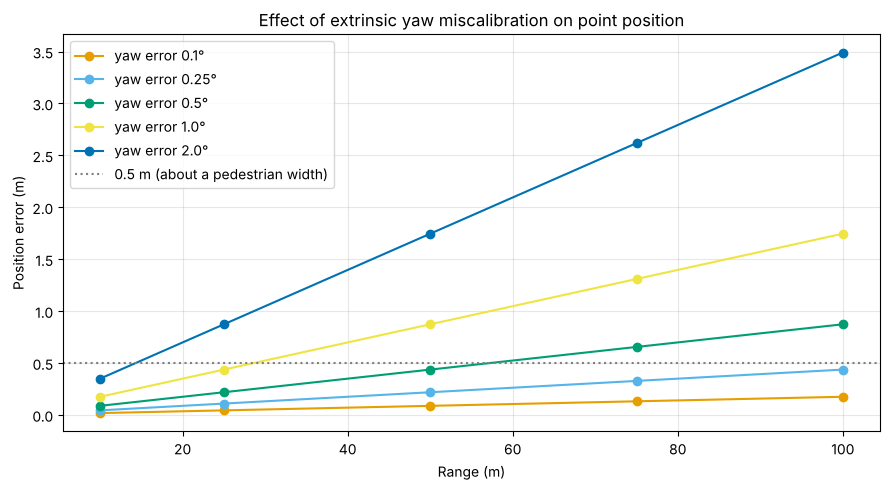

,10 m,25 m,50 m,75 m,100 m
0.1 deg,0.02,0.04,0.09,0.13,0.17
0.25 deg,0.04,0.11,0.22,0.33,0.44
0.5 deg,0.09,0.22,0.44,0.65,0.87
1.0 deg,0.17,0.44,0.87,1.31,1.75
2.0 deg,0.35,0.87,1.75,2.62,3.49


Largest yaw error that keeps the error below 0.5 m at 50 m: 0.5 deg
Motion distortion: at 108 km/h the vehicle moves 3.0 m during one 10 Hz sweep -> points must be motion-compensated (de-skewed) using odometry.


In [5]:
# Sensor mounted on the roof, 1.2 m ahead of the rear axle, 1.8 m above ground, with a nominal yaw of 0 deg
R_true = Rotation.from_euler('xyz', [0.0, 0.0, 0.0], degrees=True).as_matrix()
t_true = np.array([1.2, 0.0, 1.8])

def sensor_to_vehicle(p, R, t):
    return p @ R.T + t

p_sensor = np.array([[50.0, 0.0, -1.0], [20.0, 3.5, -1.0], [100.0, -2.0, 0.0]])
print("Sensor-frame points -> vehicle-frame points:")
for ps, pv in zip(p_sensor, sensor_to_vehicle(p_sensor, R_true, t_true)):
    print(f"  {ps} -> {np.round(pv, 2)}")

yaw_err = np.array([0.1, 0.25, 0.5, 1.0, 2.0])       # degrees
ranges = np.array([10, 25, 50, 75, 100])              # m
fig, ax = plt.subplots(figsize=(9, 5))
rows = []
for e in yaw_err:
    R_err = Rotation.from_euler('z', e, degrees=True).as_matrix() @ R_true
    lat = []
    for r in ranges:
        p = np.array([[r, 0.0, 0.0]])
        lat.append(np.linalg.norm(sensor_to_vehicle(p, R_err, t_true) - sensor_to_vehicle(p, R_true, t_true)))
    rows.append(lat)
    ax.plot(ranges, lat, 'o-', label=f'yaw error {e}°')
ax.axhline(0.5, color='grey', ls=':', label='0.5 m (about a pedestrian width)')
ax.set_xlabel('Range (m)'); ax.set_ylabel('Position error (m)')
ax.set_title('Effect of extrinsic yaw miscalibration on point position'); ax.legend()
plt.tight_layout(); plt.show()

err = pd.DataFrame(rows, index=[f'{e} deg' for e in yaw_err], columns=[f'{r} m' for r in ranges]).round(2)
display(err)
worst_ok = [e for e, row in zip(yaw_err, rows) if row[list(ranges).index(50)] < 0.5]
print(f"Largest yaw error that keeps the error below 0.5 m at 50 m: {max(worst_ok) if worst_ok else 'none'} deg")
v, sweep = 30.0, 0.1
print(f"Motion distortion: at {v*3.6:.0f} km/h the vehicle moves {v*sweep:.1f} m during one 10 Hz sweep -> "
      "points must be motion-compensated (de-skewed) using odometry.")

## 5. Point-cloud processing: ground removal and clustering

A classic (non-learned) pipeline, still used as a **safety fallback** for detecting obstacles of unknown class:

1. **Ground segmentation** — fit a plane with RANSAC and remove its inliers.
2. **Clustering** — group the remaining points by Euclidean proximity (here DBSCAN).
3. **Box fitting** — an axis-aligned bounding box per cluster.

Learned 3D detectors (PointPillars, CenterPoint) replace steps 2–3 and also predict class, orientation and velocity — see [06 Sensor fusion](06_sensor_fusion.ipynb) and [08 Driving datasets](08_driving_datasets.ipynb) for 3D detection metrics.

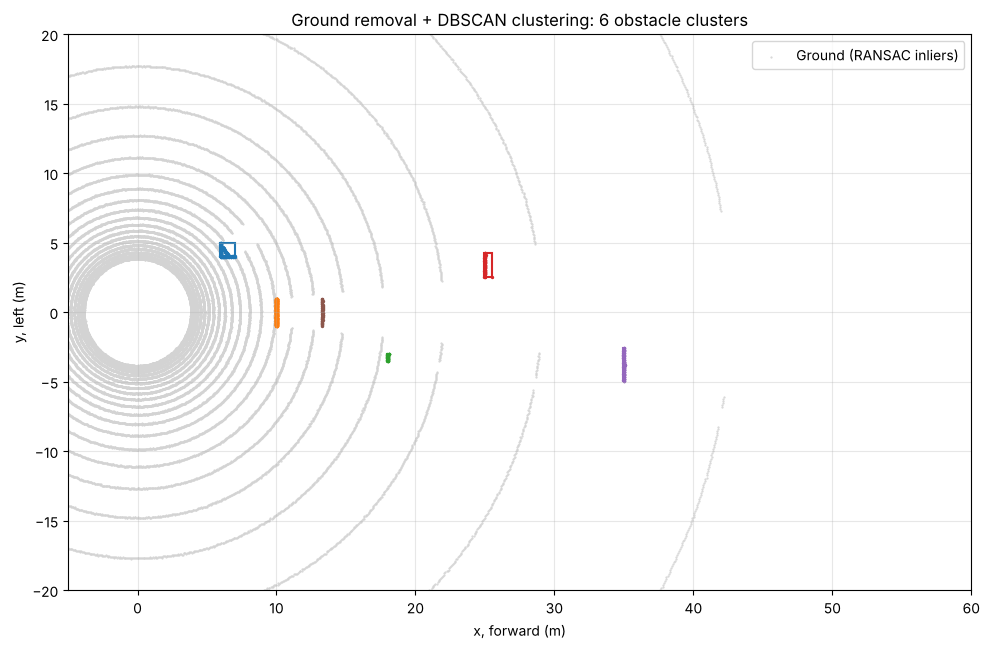

Fitted ground normal: [-0.001 -0.001  1.   ]; ground inliers: 37,198 of 37,976
Ground-truth object -> overlapping clusters:
  car ahead      :  442 LiDAR returns -> found in 2 cluster(s) with 442 points
  car left       :   64 LiDAR returns -> found in 1 cluster(s) with 61 points
  pedestrian     :   45 LiDAR returns -> found in 1 cluster(s) with 45 points
  debris (0.4 m) :  166 LiDAR returns -> found in 1 cluster(s) with 124 points
  truck          :  103 LiDAR returns -> found in 1 cluster(s) with 91 points
Objects: 5, clusters: 6, missed objects: 0, objects split into several clusters: 1
Over-segmentation: e.g. the rear face and the roof of a car are separated by a gap without returns.


In [6]:
from sklearn.cluster import DBSCAN

scene = [(10.0, 14.5, -1.0, 1.0, G, G + 1.5),        # car ahead
         (25.0, 29.5, 2.5, 4.3, G, G + 1.5),         # car, left lane
         (18.0, 18.5, -3.5, -3.0, G, G + 1.75),      # pedestrian
         (6.0, 7.0, 4.0, 5.0, G, G + 0.4),           # low debris / kerb object (unknown class)
         (35.0, 43.0, -5.0, -2.5, G, G + 3.5)]       # truck
names = ['car ahead', 'car left', 'pedestrian', 'debris (0.4 m)', 'truck']
dirs = beam_dirs(n_beams=32, h_res_deg=0.2)
tt, ii = ray_boxes(np.zeros(3), dirs, scene, max_range=60)
ok = np.isfinite(tt)
pts = dirs[ok] * (tt[ok] + rng.normal(0, 0.02, ok.sum()))[:, None]
lab = ii[ok]

def ransac_plane(p, n_iter=200, thr=0.1, rng=rng):
    best, best_in = None, None
    for _ in range(n_iter):
        s = p[rng.choice(len(p), 3, replace=False)]
        nvec = np.cross(s[1] - s[0], s[2] - s[0]); nrm = np.linalg.norm(nvec)
        if nrm < 1e-6: continue
        nvec /= nrm; dist = np.abs((p - s[0]) @ nvec)
        inl = dist < thr
        if best_in is None or inl.sum() > best_in.sum():
            best, best_in = (nvec, s[0]), inl
    return best, best_in

(normal, p0), ground_mask = ransac_plane(pts)
obst = pts[~ground_mask]
cl = DBSCAN(eps=0.7, min_samples=5).fit_predict(obst[:, :2])
n_clusters = cl.max() + 1

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(pts[ground_mask, 0], pts[ground_mask, 1], s=0.3, c='lightgrey', label='Ground (RANSAC inliers)')
cmap = plt.get_cmap('tab10')
boxes_found = []
for c in range(n_clusters):
    q = obst[cl == c]
    ax.scatter(q[:, 0], q[:, 1], s=2, color=cmap(c % 10))
    x0, y0 = q[:, :2].min(0); x1, y1 = q[:, :2].max(0)
    ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, color=cmap(c % 10), lw=1.5))
    boxes_found.append((x0, x1, y0, y1, len(q)))
ax.set_xlim(-5, 60); ax.set_ylim(-20, 20); ax.set_aspect('equal')
ax.set_xlabel('x, forward (m)'); ax.set_ylabel('y, left (m)')
ax.set_title(f'Ground removal + DBSCAN clustering: {n_clusters} obstacle clusters'); ax.legend(loc='upper right')
plt.tight_layout(); plt.show()

print(f"Fitted ground normal: {np.round(normal * np.sign(normal[2]), 3)}; ground inliers: {ground_mask.sum():,} of {len(pts):,}")
print("Ground-truth object -> overlapping clusters:")
n_split = n_missed = 0
for (x0, x1, y0, y1, z0, z1), nm in zip(scene, names):
    match = [b for b in boxes_found if b[0] < x1 + 0.3 and b[1] > x0 - 0.3 and b[2] < y1 + 0.3 and b[3] > y0 - 0.3]
    n_pts = (lab == names.index(nm)).sum()
    if not match:
        status = "NOT found"; n_missed += 1
    else:
        status = f"found in {len(match)} cluster(s) with {sum(b[4] for b in match)} points"
        n_split += len(match) > 1
    print(f"  {nm:15s}: {n_pts:4d} LiDAR returns -> {status}")
print(f"Objects: {len(scene)}, clusters: {n_clusters}, missed objects: {n_missed}, objects split into several clusters: {n_split}")
if n_split:
    print("Over-segmentation: e.g. the rear face and the roof of a car are separated by a gap without returns.")

Things to notice in the output: a single object can be split into several clusters (over-segmentation), the RANSAC threshold (0.1 m) decides whether a low object such as debris survives ground removal, and objects with very few returns may fall below DBSCAN's `min_samples`. Both are design parameters with direct safety consequences — exactly the kind of **performance insufficiency** ISO 21448 asks you to analyse.

## 6. LiDAR failure modes

| Failure mode | Mechanism | Typical effect |
|---|---|---|
| Rain, fog, snow, spray | Backscatter and attenuation by droplets/flakes | Range loss, false near-range returns ("clutter") |
| Dark / specular targets | Low or mirror-like reflectivity | Missing returns (black cars, wet road, glass) |
| Retro-reflectors | Very strong returns saturate the detector | Blooming: phantom points around signs and number plates |
| Sun and cross-talk | Ambient photons or other LiDARs | Noise points, spurious detections |
| Contamination | Mud, ice, insects on the window | Blind sectors |
| Motion distortion | Ego and object motion during the sweep | Smeared or duplicated objects unless de-skewed |
| Calibration drift | Mechanical shocks, temperature | Mis-registered points, wrong fusion associations (section 4) |
| Sparse long range | 1/d² density (section 3.4) | Small objects (children, debris) detected late |

## Safety perspective

Every row of the table above is a candidate **triggering condition** in the sense of ISO 21448:2022: the sensor is not broken, yet its output is insufficient for the intended function. A SOTIF analysis asks which of these conditions occur within the ODD, what the system does when they occur, and how much residual risk remains. For ML-based 3D detectors on top of the point cloud, ISO/PAS 8800:2024 adds questions about the training data (does it contain fog, dark cars, spray?) and about uncertainty estimation.

The author's own research applies exactly this view to LiDAR-based object detection — simulation-based evaluation of 3D detectors in a SOTIF-related use case and uncertainty evaluation to identify performance insufficiencies (see References).

Continue with: [04_SOTIF_ISO21448/02 — Triggering conditions](../04_SOTIF_ISO21448/02_triggering_conditions_and_scenarios.ipynb) · [06_AI_Safety_ISO_PAS_8800/02 — Uncertainty types](../06_AI_Safety_ISO_PAS_8800/02_uncertainty_types.ipynb).

## Key takeaways

- Pulsed ToF measures range from round-trip time (d = c·Δt/2); FMCW LiDAR additionally measures radial velocity per point.
- For an extended target, received power falls with 1/d²; for targets smaller than the beam footprint with 1/d⁴ — ranges must be quoted at a stated reflectivity.
- Point density on a cylinder of radius d is N_rev / (2π d² θ_v): ~780 points/m² at 10 m for an HDL-64E-class sensor, 100× less at 100 m.
- Returns on a pedestrian drop roughly with 1/d²; very close objects can be partly inside the near-field blind zone below the lowest beam.
- Extrinsic calibration errors grow with range (≈ d·δψ): 1° of yaw error displaces a point at 50 m by ~0.9 m; motion distortion requires de-skewing.
- LiDAR market facts change fast (Velodyne–Ouster merger 2023, Bosch exit 2023, ~US$200 units 2025, Luminar Chapter 11 Dec 2025 — as of Oct 2026).
- Weather, dark targets, retro-reflectors, contamination and sparsity are SOTIF triggering conditions, not faults.

## Self-assessment

1. A LiDAR pulse has a round-trip time of 3000 ns. How far away is the target?
2. Why do datasheets quote LiDAR range 'at 10 % reflectivity'? How does received power scale with distance for a small target?
3. Using the density formula, how much lower is the point density at 60 m than at 15 m?
4. Which yaw calibration error keeps the lateral error below 0.5 m at 50 m, and why does the requirement get tighter with range?
5. Give two LiDAR failure modes that are SOTIF triggering conditions and explain the physical mechanism.
6. How can multiple modulation frequencies extend the unambiguous range of a phase-shift LiDAR?

<details>
<summary>Show answers</summary>

1. d = c·Δt/2 = 3×10⁸ × 3×10⁻⁶ / 2 ≈ 450 m (≈ 449.7 m with c = 299 792 458 m/s).
2. Because range depends strongly on target reflectivity; 10 % represents dark objects. For an extended target P_r ∝ 1/d², for a target smaller than the beam footprint P_r ∝ 1/d⁴.
3. (60/15)² = 16 times lower.
4. From the table: errors up to about 0.5° keep it below 0.5 m (0.5° × π/180 × 50 m ≈ 0.44 m). The displacement is ≈ d·δψ, so it grows linearly with range.
5. Fog/rain: droplets scatter and absorb the beam (attenuation, backscatter clutter). Retro-reflectors: very strong returns saturate the receiver and produce blooming. Dark targets: low reflectivity gives too little return power.
6. Each frequency gives a wrapped phase with a different unambiguous range; combining them (e.g. via the Chinese remainder theorem or a coarse + fine frequency) resolves the integer number of wraps, extending the effective unambiguous range to that of the beat between the frequencies.

</details>

## References

1. Royo, S., Ballesta-Garcia, M. (2019). An Overview of Lidar Imaging Systems for Autonomous Vehicles. *Applied Sciences* 9(19), 4093. https://doi.org/10.3390/app9194093
2. Hecht, J. (2018). Lidar for Self-Driving Cars. *Optics & Photonics News* 29(1), 26–33. https://doi.org/10.1364/OPN.29.1.000026
3. Raj, T. et al. (2020). A Survey on LiDAR Scanning Mechanisms. *Electronics* 9(5), 741. https://doi.org/10.3390/electronics9050741
4. IEC 60825-1:2014. *Safety of laser products — Part 1: Equipment classification and requirements.*
5. ISO 8855:2011. *Road vehicles — Vehicle dynamics and road-holding ability — Vocabulary.*
6. ISO 21448:2022. *Road vehicles — Safety of the intended functionality.* https://www.iso.org/standard/77490.html
7. Fischler, M. A., Bolles, R. C. (1981). Random Sample Consensus. *Communications of the ACM* 24(6), 381–395. https://doi.org/10.1145/358669.358692
8. Ester, M., Kriegel, H.-P., Sander, J., Xu, X. (1996). A Density-Based Algorithm for Discovering Clusters in Large Spatial Databases with Noise. KDD-96.
9. Patel, M., Jung, R. (2024). Simulation-Based Performance Evaluation of 3D Object Detection Methods with Deep Learning for a LiDAR Point Cloud Dataset in a SOTIF-related Use Case. VEHITS 2024. https://doi.org/10.5220/0012707300003702
10. Patel, M., Jung, R. (2026). Uncertainty Evaluation to Support Safety of the Intended Functionality Analysis for Identifying Performance Insufficiencies in ML-Based LiDAR Object Detection. VEHITS 2026. https://doi.org/10.5220/0014967200004030
11. Patel, M., Jung, R. (2026). Uncertainty Representation in a SOTIF-Related Use Case with Dempster-Shafer Theory for LiDAR Sensor-Based Object Detection. CCIS (Springer). https://doi.org/10.1007/978-3-032-23187-1_10

---
**Navigation:** ← [02 Sensor modalities](02_sensor_modalities.ipynb) · [Module index](README.md) · [04 Object detection](04_object_detection.ipynb) →